# Задача 7. Векторизация вычислений

Фотоны хранятся в массиве NumPy формы `(n, 3)`. Пересечение
всех лучей со сферой, поиск попаданий и пуассоновский отклик
вычисляются операциями над массивами без цикла по фотонам.
Для контроля результат сравнивается со скалярной реализацией.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt

from src.model import Detector, Source, isotropic_directions

detector = Detector(R=2.0, N=40, r=0.10, a=0.5)
source = Source(Y=10_000.0, position=np.array([0.0, 0.0, 0.7]))
directions = isotropic_directions(100_000, np.random.default_rng(7101))

start = time.perf_counter()
vectorized_indices = detector.trace_photons(source.position, directions)
vectorized_time = time.perf_counter() - start

start = time.perf_counter()
scalar_indices = detector.trace_photons_scalar(source.position, directions)
scalar_time = time.perf_counter() - start

assert np.array_equal(vectorized_indices, scalar_indices)
speedup = scalar_time / vectorized_time
print(f"Векторизованно: {vectorized_time:.4f} с")
print(f"Цикл по фотонам: {scalar_time:.4f} с")
print(f"Ускорение: {speedup:.1f} раза")

Векторизованно: 0.0143 с
Цикл по фотонам: 0.4421 с
Ускорение: 30.8 раза


In [2]:
detected = vectorized_indices[vectorized_indices >= 0]
hits_per_pmt = np.bincount(detected, minlength=detector.N)
charge_per_pmt = detector.response.sample_total(
    hits_per_pmt, np.random.default_rng(7102)
)
print("Массив направлений:", directions.shape, directions.dtype)
print("Массив индексов ФЭУ:", vectorized_indices.shape)
print("Попавших фотонов:", len(detected))
print("Полный заряд:", int(charge_per_pmt.sum()))

Массив направлений: (100000, 3) float64
Массив индексов ФЭУ: (100000,)
Попавших фотонов: 2492
Полный заряд: 1219


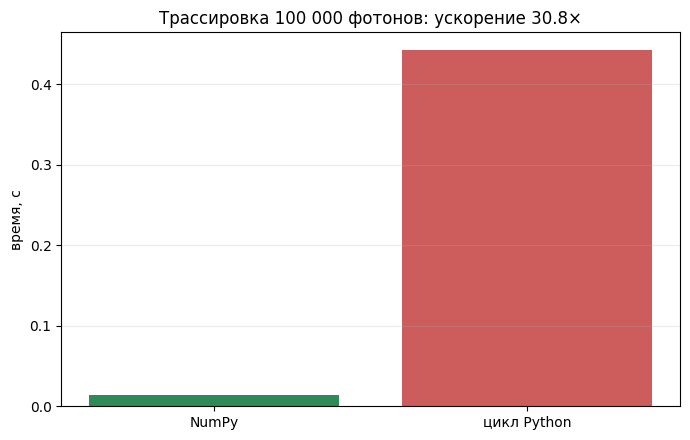

In [3]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.bar(["NumPy", "цикл Python"], [vectorized_time, scalar_time],
       color=["seagreen", "indianred"])
ax.set(ylabel="время, с", title=f"Трассировка 100 000 фотонов: ускорение {speedup:.1f}×")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
fig.savefig("figures/task7_vectorization_benchmark.png", dpi=180, bbox_inches="tight")
plt.show()

**Вывод.** Векторизованный и скалярный алгоритмы дают строго
одинаковые индексы ФЭУ, но NumPy выполняет основную линейную
алгебру в скомпилированном коде и заметно сокращает время работы.